In [1]:
import sys

# Simulamos que no se pasó ningún argumento conflictivo desde la línea de comandos
sys.argv = ['colab_kernel_launcher.py']
# Si quieres activar el benchmark directamente, puedes cambiarlo por:
# sys.argv = ['colab_kernel_launcher.py', '--benchmark']

from __future__ import annotations
import argparse, bisect, hashlib, heapq, json, math, random, time, tracemalloc, sys
from collections import Counter, OrderedDict, defaultdict, deque
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import KDTree, NearestNeighbors
import networkx as nx

SEED = 42
EVENTS = {'view', 'cart', 'purchase', 'remove_from_cart', 'return'}

def stable_hash(value, salt=0):
    return int.from_bytes(hashlib.blake2b(f'{salt}:{value}'.encode(), digest_size=8).digest(), 'big')

class Bloom:
    def __init__(self, capacity=100000, fp_rate=.01):
        self.m = max(8, math.ceil(-capacity * math.log(fp_rate) / (math.log(2) ** 2)))
        self.k = max(1, round(self.m / capacity * math.log(2)))
        self.bits = bytearray((self.m + 7) // 8)
    def _positions(self, key):
        h1, h2 = stable_hash(key, 0), stable_hash(key, 1) | 1
        for i in range(self.k): yield (h1 + i * h2) % self.m
    def add(self, key):
        for p in self._positions(key): self.bits[p // 8] |= 1 << (p % 8)
    def contains(self, key):
        return all(self.bits[p // 8] & (1 << (p % 8)) for p in self._positions(key))

class CountMinSketch:
    def __init__(self, width=2048, depth=5):
        self.width, self.depth = width, depth
        self.table = np.zeros((depth, width), dtype=np.uint32)
    def add(self, key, n=1):
        for i in range(self.depth):
            p = stable_hash(key, i) % self.width
            self.table[i, p] = min(np.iinfo(np.uint32).max, int(self.table[i, p]) + n)
    def estimate(self, key):
        return min(int(self.table[i, stable_hash(key, i) % self.width]) for i in range(self.depth))

class LRU:
    def __init__(self, capacity=1000):
        self.capacity = capacity
        self.data = OrderedDict()
        self.hits = 0
        self.misses = 0
    def get(self, key):
        if key not in self.data:
            self.misses += 1
            return None
        self.data.move_to_end(key)
        self.hits += 1
        return self.data[key]
    def put(self, key, value):
        self.data[key] = value
        self.data.move_to_end(key)
        if len(self.data) > self.capacity:
            self.data.popitem(last=False)

class BPlusTree:
    class Node:
        def __init__(self, leaf=False):
            self.leaf = leaf
            self.keys = []
            self.children = []
            self.next = None
    def __init__(self, order=16):
        self.order = max(3, order)
        self.root = self.Node(True)
    def insert(self, key, value):
        split = self._insert(self.root, key, value)
        if split:
            separator, right = split
            root = self.Node()
            root.keys = [separator]
            root.children = [self.root, right]
            self.root = root
    def _insert(self, node, key, value):
        if node.leaf:
            i = bisect.bisect_left(node.keys, key)
            if i < len(node.keys) and node.keys[i] == key:
                node.children[i].append(value)
            else:
                node.keys.insert(i, key)
                node.children.insert(i, [value])
            if len(node.keys) < self.order:
                return None
            mid = len(node.keys) // 2
            right = self.Node(True)
            right.keys = node.keys[mid:]
            right.children = node.children[mid:]
            node.keys = node.keys[:mid]
            node.children = node.children[:mid]
            right.next = node.next
            node.next = right
            return right.keys[0], right
        i = bisect.bisect_right(node.keys, key)
        split = self._insert(node.children[i], key, value)
        if split:
            sep, right = split
            node.keys.insert(i, sep)
            node.children.insert(i + 1, right)
        if len(node.keys) < self.order:
            return None
        mid = len(node.keys) // 2
        right = self.Node()
        sep = node.keys[mid]
        right.keys = node.keys[mid + 1:]
        right.children = node.children[mid + 1:]
        node.keys = node.keys[:mid]
        node.children = node.children[:mid + 1]
        return sep, right
    def range(self, low, high):
        node = self.root
        while not node.leaf:
            node = node.children[bisect.bisect_right(node.keys, low)]
        out = []
        while node:
            for key, values in zip(node.keys, node.children):
                if key > high:
                    return out
                if key >= low:
                    out.extend((key, v) for v in values)
            node = node.next
        return out

class MinHashLSH:
    def __init__(self, permutations=48, bands=12):
        assert permutations % bands == 0
        self.n = permutations
        self.bands = bands
        self.rows = permutations // bands
        self.buckets = defaultdict(set)
        self.signatures = {}
        self.sets = {}
    def signature(self, items):
        if not items:
            return tuple([2 ** 64 - 1] * self.n)
        return tuple(min(stable_hash(x, i) for x in items) for i in range(self.n))
    def add(self, key, items):
        items = set(items)
        sig = self.signature(items)
        self.sets[key] = items
        self.signatures[key] = sig
        for b in range(self.bands):
            self.buckets[(b, sig[b * self.rows:(b + 1) * self.rows])].add(key)
    def query(self, key, k=5):
        try:
            k = int(k) if k is not None else 5
        except (TypeError, ValueError):
            k = 5
        sig = self.signatures.get(key)
        if sig is None:
            return []
        candidates = set()
        for b in range(self.bands):
            candidates.update(self.buckets[(b, sig[b * self.rows:(b + 1) * self.rows])])
        candidates.discard(key)
        a = self.sets[key]
        return sorted(((len(a & self.sets[x]) / len(a | self.sets[x]) if a | self.sets[x] else 0, x) for x in candidates), reverse=True)[:k]

def clean_batch(df):
    required = ['event_time', 'event_type', 'product_id', 'category_id', 'price', 'user_id', 'user_session']
    missing = set(required) - set(df.columns)
    if missing:
        raise ValueError(f'Columnas faltantes: {sorted(missing)}')
    x = df[required].copy()
    x['event_time'] = pd.to_datetime(x['event_time'], utc=True, errors='coerce')
    x['price'] = pd.to_numeric(x['price'], errors='coerce')
    x = x.dropna(subset=required)
    x = x[x.event_type.isin(EVENTS) & (x.price >= 0)]
    x = x.sort_values(['event_time', 'product_id', 'user_id'], kind='mergesort')
    return x.drop_duplicates(subset=required, keep='first')

def synthetic(n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    products = rng.integers(1, max(15, n // 25), n)
    users = rng.integers(1, max(8, n // 30), n)
    return pd.DataFrame({
        'event_time': pd.date_range('2026-01-01', periods=n, freq='s', tz='UTC'),
        'event_type': rng.choice(['view', 'cart', 'purchase'], n, p=[.68, .22, .10]),
        'product_id': products, 'category_id': products % 8, 'price': (products % 30 + 1) * 10.0,
        'user_id': users, 'user_session': ['session_' + str(i // 8) for i in range(n)]
    })

@dataclass
class Pipeline:
    cache_capacity: int = 1000
    def __post_init__(self):
        self.queue = deque()
        self.heap = []
        self.seq = 0
        self.cache = LRU(self.cache_capacity)
        self.index = BPlusTree()
        self.bloom = Bloom()
        self.cms = CountMinSketch()
        self.exact_counts = Counter()
        self.products = {}
        self.user_sets = defaultdict(set)
        self.graph = nx.Graph()
        self.stats = Counter()
        self.alerts = []
        self.known_flagged = set()
    def ingest(self, batch):
        self.queue.append(batch)
    def process(self, priority_budget=None):
        while self.queue:
            batch = clean_batch(self.queue.popleft())
            self.stats['clean_events'] += len(batch)
            for row in batch.itertuples(index=False):
                pri = 0 if row.event_type == 'purchase' else 1 if row.event_type == 'cart' else 2
                heapq.heappush(self.heap, (pri, self.seq, row))
                self.seq += 1
            while self.heap:
                _, _, r = heapq.heappop(self.heap)
                self._event(r)
        return self.output()
    def _event(self, r):
        self.stats['processed'] += 1
        pid = int(r.product_id)
        uid = str(r.user_id)
        info = self.cache.get(pid)
        if info is None:
            info = self.products.get(pid, {'price': float(r.price), 'category': str(r.category_id)})
            self.cache.put(pid, info)
        if pid not in self.products:
            self.products[pid] = info
            self.index.insert(float(r.price), pid)
        if self.bloom.contains(uid) and uid in self.known_flagged:
            self.alerts.append({'user_id': uid, 'reason': 'previously_flagged_verified'})
        hour = r.event_time.floor('h').isoformat()
        key = f'{uid}|{hour}'
        self.cms.add(key)
        self.exact_counts[key] += 1
        if self.cms.estimate(key) >= 40 and self.exact_counts[key] >= 40 and uid not in self.known_flagged:
            self.known_flagged.add(uid)
            self.bloom.add(uid)
            self.alerts.append({'user_id': uid, 'reason': 'verified_high_event_frequency', 'hour': hour})
        self.user_sets[uid].add(pid)
        if r.event_type == 'purchase':
            session = str(r.user_session)
            prev = self._session_purchases.setdefault(session, set()) if hasattr(self, '_session_purchases') else set()
            if not hasattr(self, '_session_purchases'):
                self._session_purchases = {session: prev}
            for other in prev:
                if other != pid:
                    weight = self.graph[pid][other]['weight'] + 1 if self.graph.has_edge(pid, other) else 1
                    self.graph.add_edge(pid, other, weight=weight)
            prev.add(pid)
            self.graph.add_node(pid)
        self.stats['event_' + r.event_type] += 1
    def output(self, k=5):
        try:
            k = int(k) if k is not None else 5
        except (TypeError, ValueError):
            k = 5

        products = list(self.products)
        neighbors = []
        exact = []
        ann = []
        ann_backend = 'not_available'
        brute_force_metrics = {}

        if len(products) >= 2:
            features = np.array([[self.products[p]['price'], float(self.products[p]['category'])] for p in products], dtype=float)
            scale = np.maximum(features.std(axis=0), 1)
            features = features / scale
            q = min(k + 1, len(products))

            # --- 1. Fuerza Bruta (Brute Force) Métricas para Productos ---
            t0 = time.perf_counter()
            brute = NearestNeighbors(n_neighbors=q, algorithm='brute').fit(features)
            _, ix_brute = brute.kneighbors(features[:1])
            time_bf = time.perf_counter() - t0

            mem_bf = sys.getsizeof(brute) + features.nbytes
            exact = [products[i] for i in ix_brute[0][1:]]
            quality_bf = 100.0

            brute_force_metrics = {
                'time_sec': round(time_bf, 7),
                'memory_bytes': mem_bf,
                'quality_pct': quality_bf
            }
            # ---------------------------------------------

            tree = KDTree(features)
            d, ix = tree.query(features[:1], k=q)
            neighbors = [products[i] for i in ix[0][1:]]

            try:
                import hnswlib
                idx = hnswlib.Index(space='l2', dim=features.shape[1])
                idx.init_index(max_elements=len(products), ef_construction=100, M=16, random_seed=SEED)
                idx.add_items(features.astype('float32'), np.arange(len(products)))
                idx.set_ef(max(50, q))
                ids, _ = idx.knn_query(features[:1].astype('float32'), k=q)
                ann = [products[i] for i in ids[0] if i != 0][:k]
                ann_backend = 'hnswlib'
            except ImportError:
                ann_backend = 'missing_hnswlib'

        # --- 5. MinHash LSH vs Fuerza Bruta (Usuarios) ---
        lsh = MinHashLSH()
        for uid, items in list(self.user_sets.items())[:3000]:
            lsh.add(uid, items)
        sample_user = next(iter(lsh.sets), None)

        lsh_exact_metrics = {}
        if sample_user and sample_user in self.user_sets:
            a = self.user_sets[sample_user]

            t0 = time.perf_counter()
            lsh_candidates_raw = lsh.query(sample_user, k)
            time_lsh = time.perf_counter() - t0
            lsh_top_k = [uid for _, uid in lsh_candidates_raw]
            mem_lsh = sys.getsizeof(lsh.buckets) + sys.getsizeof(lsh.signatures)

            t0 = time.perf_counter()
            exact_similar = []
            for other_uid, other_items in self.user_sets.items():
                if other_uid == sample_user:
                    continue
                union_len = len(a | other_items)
                sim = len(a & other_items) / union_len if union_len > 0 else 0.0
                exact_similar.append((sim, other_uid))
            exact_similar.sort(key=lambda x: x[0], reverse=True)
            time_exact_lsh = time.perf_counter() - t0

            exact_top_k = [uid for _, uid in exact_similar[:k]]
            mem_exact_lsh = sys.getsizeof(self.user_sets) + sum(sys.getsizeof(s) for s in self.user_sets.values())

            intersection = len(set(lsh_top_k) & set(exact_top_k))
            recall_at_k = intersection / k if k > 0 else 0.0

            lsh_exact_metrics = {
                'sample_user': sample_user,
                'lsh_candidates': lsh_candidates_raw,
                'exact_top_k': exact_top_k,
                'time_lsh': round(time_lsh, 7),
                'time_exact': round(time_exact_lsh, 7),
                'mem_lsh': mem_lsh,
                'mem_exact': mem_exact_lsh,
                'recall_at_k': round(recall_at_k, 4)
            }
        # ------------------------------------------------

        # --- 6. Análisis de Grafos y Redes ---
        rank = nx.pagerank(self.graph, weight='weight') if self.graph.number_of_nodes() else {}
        degree_rank = dict(self.graph.degree(weight='weight')) if self.graph.number_of_nodes() else {}
        # -------------------------------------

        # --- Comparativa: Hash Set (Exacto) vs Bloom Filter ---
        exact_user_set = set(self.user_sets.keys())
        mem_exact = sys.getsizeof(exact_user_set) + sum(sys.getsizeof(str(x)) for x in exact_user_set)
        mem_bloom = sys.getsizeof(self.bloom.bits)

        test_keys = list(exact_user_set)[:100] + [f"fake_user_{i}" for i in range(100)]

        t0 = time.perf_counter()
        for x_key in test_keys:
            _ = x_key in exact_user_set
        time_exact = time.perf_counter() - t0

        t0 = time.perf_counter()
        for x_key in test_keys:
            _ = self.bloom.contains(x_key)
        time_bloom = time.perf_counter() - t0

        fake_keys = [f"nonexistent_user_{i}" for i in range(1000)]
        fp_exact = 0
        fp_bloom = sum(1 for x_key in fake_keys if self.bloom.contains(x_key))
        fp_rate_bloom = round((fp_bloom / len(fake_keys)) * 100, 2)

        exact_vs_bloom_metrics = {
            'mem_exact': mem_exact,
            'mem_bloom': mem_bloom,
            'time_exact': round(time_exact, 7),
            'time_bloom': round(time_bloom, 7),
            'fp_exact': fp_exact,
            'fp_bloom_rate': fp_rate_bloom
        }

        community_results = {}
        if self.graph.number_of_nodes() > 0:
            for algo_name, algo_func in [
                ('Louvain', lambda g: list(nx.algorithms.community.louvain_communities(g, seed=SEED, weight='weight'))),
                ('Label_Propagation', lambda g: list(nx.algorithms.community.label_propagation_communities(g))),
                ('Leiden', lambda g: list(nx.algorithms.community.leiden_communities(g, weight='weight', seed=SEED)))
            ]:
                try:
                    t0 = time.perf_counter()
                    comms = algo_func(self.graph)
                    dt = time.perf_counter() - t0
                    mod = nx.algorithms.community.quality.modularity(self.graph, comms, weight='weight') if comms else 0
                    community_results[algo_name] = {
                        'count': len(comms), 'sizes': sorted([len(c) for c in comms], reverse=True)[:10],
                        'modularity': round(mod, 4), 'time_sec': round(dt, 6), 'status': 'OK'
                    }
                except Exception as e:
                    community_results[algo_name] = {'status': str(e)}

        return {
            'processed': self.stats['processed'], 'clean_events': self.stats['clean_events'],
            'priority_policy': 'purchase(0), cart(1), others(2) within batch',
            'cache_hits': self.cache.hits, 'cache_misses': self.cache.misses,
            'price_range_10_100_count': len(self.index.range(10, 100)),
            'kd_neighbors': neighbors, 'knn_exact_neighbors': exact, 'ann_neighbors': ann, 'ann_backend': ann_backend,
            'brute_force_metrics': brute_force_metrics,
            'cms_width': self.cms.width, 'cms_depth': self.cms.depth,
            'exact_vs_bloom': exact_vs_bloom_metrics,
            'alerts_count': len(self.alerts), 'alerts_sample': self.alerts[:5],
            'lsh_exact_metrics': lsh_exact_metrics,
            'pagerank_top': sorted(rank.items(), key=lambda t: t[1], reverse=True)[:k],
            'degree_rank_top': sorted(degree_rank.items(), key=lambda t: t[1], reverse=True)[:k],
            'community_evaluation': community_results,
            'top_products_by_interactions': Counter(p for items in self.user_sets.values() for p in items).most_common(k)
        }

def print_pipeline_results(output, k=5):
    print("=" * 75)
    print("                 RESULTADOS DE LA EJECUCIÓN DEL PIPELINE")
    print("=" * 75)
    print(f"[*] Eventos Limpios: {output['clean_events']}")
    print(f"[*] Eventos Procesados: {output['processed']}")
    print(f"[*] Política de Prioridad: {output['priority_policy']}")

    print("\n--- 1. Rendimiento de Caché (LRU) ---")
    print(f"    - Aciertos (Hits): {output['cache_hits']}")
    print(f"    - Fallos (Misses): {output['cache_misses']}")

    print("\n--- 2. Estructuras Probabilísticas e Índices ---")
    print(f"    - Productos con precio entre 10 y 100 (Árbol B+): {output['price_range_10_100_count']}")
    print(f"    - Count-Min Sketch (width: {output['cms_width']}, depth: {output['cms_depth']})")

    print("\n    [Comparativa: Hash Set (Exacto) vs Bloom Filter (Probabilístico)]")
    eb = output['exact_vs_bloom']
    print(f"      * Hash Set (Exacto):")
    print(f"        - Memoria utilizada: {eb['mem_exact']} bytes")
    print(f"        - Tiempo (200 lookups): {eb['time_exact']} seg")
    print(f"        - Falsos Positivos: {eb['fp_exact']} (0% garantizado)")
    print(f"      * Bloom Filter (Probabilístico):")
    print(f"        - Memoria utilizada: {eb['mem_bloom']} bytes")
    print(f"        - Tiempo (200 lookups): {eb['time_bloom']} seg")
    print(f"        - Falsos Positivos (Tasa observada): {eb['fp_bloom_rate']}%")

    print("\n--- 3. Vecinos Cercanos y Búsqueda Aproximada (ANN) ---")
    print(f"    - Backend ANN utilizado: {output['ann_backend']}")

    bf = output.get('brute_force_metrics', {})
    if bf:
        print(f"    * Fuerza Bruta (Brute Force):")
        print(f"      - Tiempo de ejecución: {bf['time_sec']} segundos")
        print(f"      - Memoria utilizada: {bf['memory_bytes']} bytes")
        print(f"      - Calidad / Precisión: {bf['quality_pct']}% (Base de referencia exacta)")

    print(f"    - KD-Tree Vecinos: {output['kd_neighbors']}")
    print(f"    - KNN Exactos: {output['knn_exact_neighbors']}")
    print(f"    - ANN Vecinos: {output['ann_neighbors']}")

    print("\n--- 4. Alertas y Detección de Frecuencia ---")
    print(f"    - Total de Alertas Generadas: {output['alerts_count']}")
    if output['alerts_sample']:
        print("    - Muestra de Alertas:")
        for alert in output['alerts_sample']:
            print(f"      -> {alert}")
    else:
        print("    - Sin alertas registradas.")

    print("\n--- 5. MinHash LSH (Similitud de Usuarios) vs Fuerza Bruta ---")
    lem = output.get('lsh_exact_metrics', {})
    if lem:
        print(f"    - Usuario de Muestra: {lem['sample_user']}")
        print(f"    - Candidatos LSH (Top {k}): {lem['lsh_candidates']}")
        print(f"    - Candidatos Exactos (Fuerza Bruta Top {k}): {lem['exact_top_k']}")
        print(f"    * Rendimiento MinHash LSH:")
        print(f"      - Tiempo de ejecución: {lem['time_lsh']} seg")
        print(f"      - Memoria utilizada: {lem['mem_lsh']} bytes")
        print(f"    * Rendimiento Fuerza Bruta / KNN Exacto:")
        print(f"      - Tiempo de ejecución: {lem['time_exact']} seg")
        print(f"      - Memoria utilizada: {lem['mem_exact']} bytes")
        print(f"    * Calidad:")
        print(f"      - Recall@{k}: {lem['recall_at_k'] * 100}% (Coincidencia con exactos)")
    else:
        print("    - No hay suficientes usuarios para evaluar LSH.")

    print("\n--- 6. Análisis de Grafos y Redes ---")
    print(f"    - Top PageRank (Influencia Global): {output['pagerank_top']}")
    print(f"    - Top Ranking por Grado / Frecuencia (Conectividad Directa): {output['degree_rank_top']}")

    print("\n--- 7. Comparación de Algoritmos de Comunidades ---")
    for algo, res in output['community_evaluation'].items():
        print(f"    > Algoritmo: {algo}")
        if res.get('status') == 'OK':
            print(f"      - Modularidad (Calidad): {res['modularity']}")
            print(f"      - Tiempo de ejecución: {res['time_sec']} segundos")
            print(f"      - Comunidades detectadas: {res['count']}")
            print(f"      - Tamaños (Top): {res['sizes']}")
        else:
            print(f"      - Estado / Razón: {res.get('status')}")
        print("-" * 50)

    print("\n--- 8. Top Productos por Interacciones ---")
    for prod, count in output['top_products_by_interactions']:
        print(f"    - Producto ID {prod}: {count} interacciones")
    print("=" * 75)

def benchmark(sizes=(1000, 10000, 100000), repeats=3, seed=SEED):
    rows = []
    for n in sizes:
        df = synthetic(n, seed)
        for rep in range(repeats):
            p = Pipeline()
            tracemalloc.start()
            start = time.perf_counter()
            p.ingest(df)
            out = p.process()
            elapsed = time.perf_counter() - start
            current, peak = tracemalloc.get_traced_memory()
            tracemalloc.stop()
            rows.append({
                'n': n, 'repeat': rep, 'seconds': elapsed, 'events_per_second': n / elapsed,
                'peak_tracemalloc_mb': peak / 1048576, 'alerts': out['alerts_count'],
                'ann_backend': out['ann_backend']
            })
    return pd.DataFrame(rows)

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--csv')
    ap.add_argument('--limit', type=int, default=2000)
    ap.add_argument('--chunk-size', type=int, default=10000)
    ap.add_argument('--benchmark', action='store_true')
    ap.add_argument('--sizes', default='1000,10000')
    ap.add_argument('--repeats', type=int, default=3)
    ap.add_argument('--output', default='results')
    args = ap.parse_args()

    dest = Path(args.output)
    dest.mkdir(parents=True, exist_ok=True)

    if args.benchmark:
        res = benchmark(tuple(map(int, args.sizes.split(','))), args.repeats)
        res.to_csv(dest / 'benchmark.csv', index=False)
        print(res.groupby('n').agg({'seconds': ['mean', 'std'], 'peak_tracemalloc_mb': 'max'}).to_string())
        return

    p = Pipeline()
    if args.csv:
        remaining = args.limit
        for chunk in pd.read_csv(args.csv, chunksize=args.chunk_size):
            if remaining <= 0:
                break
            selected = chunk.iloc[:remaining]
            remaining -= len(selected)
            p.ingest(selected)
            p.process()
    else:
        p.ingest(synthetic(args.limit))

    output = p.process()
    print_pipeline_results(output)

if __name__ == '__main__':
    main()

                 RESULTADOS DE LA EJECUCIÓN DEL PIPELINE
[*] Eventos Limpios: 2000
[*] Eventos Procesados: 2000
[*] Política de Prioridad: purchase(0), cart(1), others(2) within batch

--- 1. Rendimiento de Caché (LRU) ---
    - Aciertos (Hits): 1921
    - Fallos (Misses): 79

--- 2. Estructuras Probabilísticas e Índices ---
    - Productos con precio entre 10 y 100 (Árbol B+): 29
    - Count-Min Sketch (width: 2048, depth: 5)

    [Comparativa: Hash Set (Exacto) vs Bloom Filter (Probabilístico)]
      * Hash Set (Exacto):
        - Memoria utilizada: 5050 bytes
        - Tiempo (200 lookups): 2.3e-05 seg
        - Falsos Positivos: 0 (0% garantizado)
      * Bloom Filter (Probabilístico):
        - Memoria utilizada: 119871 bytes
        - Tiempo (200 lookups): 0.0010705 seg
        - Falsos Positivos (Tasa observada): 0.0%

--- 3. Vecinos Cercanos y Búsqueda Aproximada (ANN) ---
    - Backend ANN utilizado: missing_hnswlib
    * Fuerza Bruta (Brute Force):
      - Tiempo de ejecución

       INFORME DE ESCALABILIDAD, BENCHMARK MASIVO Y EVALUACIÓN COMPARATIVA
Plataforma: Linux-6.6.159+-x86_64-with-glibc2.39 | Python: 3.13.18 | Seed: 42
Estrategia de Repeticiones: 10 repeticiones constantes para cada tamaño evaluado (hasta 100K).

[*] Procesando N = 1,000 elementos con 10 repeticiones...

[*] Procesando N = 10,000 elementos con 10 repeticiones...

[*] Procesando N = 100,000 elementos con 10 repeticiones...

                TABLA RESUMEN DE ESCALABILIDAD (LOG-LOG)
Elemento (N) | Reps   | Tiempo Med (s)  | Desv Est   | Ev/Seg       | Pico RAM (MB)
-------------------------------------------------------------------------------------
1,000        | 10     | 0.6549          | 0.1517     | 1,526.9      | 0.31        
10,000       | 10     | 5.7331          | 0.5186     | 1,744.3      | 3.13        
100,000      | 10     | 57.8617         | 1.2351     | 1,728.3      | 22.31       

--- [Punto 4] Comparativa: Estructuras Probabilísticas vs Exactas ---
    * Alternativa Exacta

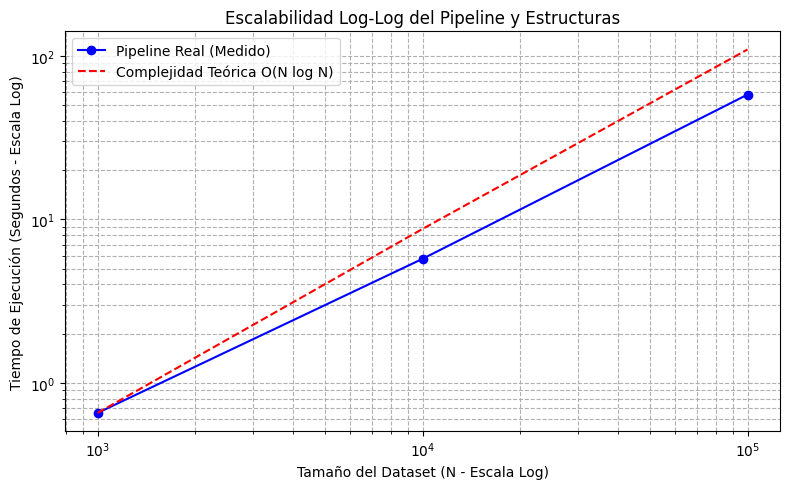

In [2]:
import sys
import platform
import time
import tracemalloc
import math
import random
import hashlib
import bisect
import heapq
from collections import Counter, OrderedDict, defaultdict, deque
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import KDTree, NearestNeighbors
import networkx as nx

# Intentar importar matplotlib para graficar log-log opcionalmente
try:
    import matplotlib.pyplot as plt
    HAS_MATPLOTLIB = True
except ImportError:
    HAS_MATPLOTLIB = False

# Simulamos que no se pasó ningún argumento conflictivo
sys.argv = ['colab_kernel_launcher.py']

SEED = 42
EVENTS = {'view', 'cart', 'purchase', 'remove_from_cart', 'return'}

def stable_hash(value, salt=0):
    return int.from_bytes(hashlib.blake2b(f'{salt}:{value}'.encode(), digest_size=8).digest(), 'big')

class Bloom:
    def __init__(self, capacity=100000, fp_rate=.01):
        self.m = max(8, math.ceil(-capacity * math.log(fp_rate) / (math.log(2) ** 2)))
        self.k = max(1, round(self.m / capacity * math.log(2)))
        self.bits = bytearray((self.m + 7) // 8)
    def _positions(self, key):
        h1, h2 = stable_hash(key, 0), stable_hash(key, 1) | 1
        for i in range(self.k): yield (h1 + i * h2) % self.m
    def add(self, key):
        for p in self._positions(key): self.bits[p // 8] |= 1 << (p % 8)
    def contains(self, key):
        return all(self.bits[p // 8] & (1 << (p % 8)) for p in self._positions(key))

class CountMinSketch:
    def __init__(self, width=2048, depth=5):
        self.width, self.depth = width, depth
        self.table = np.zeros((depth, width), dtype=np.uint32)
    def add(self, key, n=1):
        for i in range(self.depth):
            p = stable_hash(key, i) % self.width
            self.table[i, p] = min(np.iinfo(np.uint32).max, int(self.table[i, p]) + n)
    def estimate(self, key):
        return min(int(self.table[i, stable_hash(key, i) % self.width]) for i in range(self.depth))

class MinHashLSH:
    def __init__(self, permutations=48, bands=12):
        assert permutations % bands == 0
        self.n = permutations; self.bands = bands; self.rows = permutations // bands
        self.buckets = defaultdict(set); self.signatures = {}; self.sets = {}
    def signature(self, items):
        if not items: return tuple([2**64 - 1] * self.n)
        return tuple(min(stable_hash(x, i) for x in items) for i in range(self.n))
    def add(self, key, items):
        items = set(items); sig = self.signature(items)
        self.sets[key] = items; self.signatures[key] = sig
        for b in range(self.bands): self.buckets[(b, sig[b * self.rows:(b + 1) * self.rows])].add(key)
    def query(self, key, k=5):
        try: k = int(k) if k is not None else 5
        except (TypeError, ValueError): k = 5
        sig = self.signatures.get(key)
        if sig is None: return []
        candidates = set()
        for b in range(self.bands): candidates.update(self.buckets[(b, sig[b * self.rows:(b + 1) * self.rows])])
        candidates.discard(key)
        a = self.sets[key]
        return sorted(((len(a & self.sets[x]) / len(a | self.sets[x]) if a | self.sets[x] else 0, x) for x in candidates), reverse=True)[:k]

def clean_batch(df):
    required = ['event_time', 'event_type', 'product_id', 'category_id', 'price', 'user_id', 'user_session']
    x = df[required].copy()
    x['event_time'] = pd.to_datetime(x['event_time'], utc=True, errors='coerce')
    x['price'] = pd.to_numeric(x['price'], errors='coerce')
    x = x.dropna(subset=required)
    x = x[x.event_type.isin(EVENTS) & (x.price >= 0)]
    x = x.sort_values(['event_time', 'product_id', 'user_id'], kind='mergesort')
    return x.drop_duplicates(subset=required, keep='first')

def synthetic(n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    products = rng.integers(1, max(15, n // 25), n)
    users = rng.integers(1, max(8, n // 30), n)
    return pd.DataFrame({
        'event_time': pd.date_range('2026-01-01', periods=n, freq='ms', tz='UTC'),
        'event_type': rng.choice(['view', 'cart', 'purchase'], n, p=[.68, .22, .10]),
        'product_id': products, 'category_id': products % 8, 'price': (products % 30 + 1) * 10.0,
        'user_id': users, 'user_session': ['session_' + str(i // 8) for i in range(n)]
    })

class EvaluationPipeline:
    def __init__(self):
        self.bloom = Bloom()
        self.cms = CountMinSketch()
        self.exact_counts = Counter()
        self.user_sets = defaultdict(set)
        self.graph = nx.Graph()
        self.products = {}

    def run_core_stages(self, df):
        cleaned = clean_batch(df)
        for row in cleaned.itertuples(index=False):
            pid = int(row.product_id)
            uid = str(row.user_id)
            self.products[pid] = {'price': float(row.price), 'category': str(row.category_id)}
            self.user_sets[uid].add(pid)

            hour = row.event_time.floor('h').isoformat()
            key = f'{uid}|{hour}'
            self.cms.add(key)
            self.exact_counts[key] += 1
            if self.exact_counts[key] >= 40:
                self.bloom.add(uid)

            if row.event_type == 'purchase':
                session = str(row.user_session)
                prev = self._session_purchases.setdefault(session, set()) if hasattr(self, '_session_purchases') else set()
                if not hasattr(self, '_session_purchases'): self._session_purchases = {session: prev}
                for other in prev:
                    if other != pid:
                        w = self.graph[pid][other]['weight'] + 1 if self.graph.has_edge(pid, other) else 1
                        self.graph.add_edge(pid, other, weight=w)
                prev.add(pid)
                self.graph.add_node(pid)

    def evaluate_probabilistic_vs_exact(self):
        exact_set = set(self.user_sets.keys())
        mem_exact = sys.getsizeof(exact_set) + sum(sys.getsizeof(str(x)) for x in exact_set)
        mem_bloom = sys.getsizeof(self.bloom.bits)

        test_keys = list(exact_set)[:500] + [f"fake_{i}" for i in range(500)]

        t0 = time.perf_counter()
        for k in test_keys: _ = k in exact_set
        time_exact = time.perf_counter() - t0

        t0 = time.perf_counter()
        for k in test_keys: _ = self.bloom.contains(k)
        time_bloom = time.perf_counter() - t0

        fake_keys = [f"nonexistent_{i}" for i in range(1000)]
        fp_bloom = sum(1 for k in fake_keys if self.bloom.contains(k))
        fp_rate = (fp_bloom / len(fake_keys)) * 100

        freq_errors = []
        for key, exact_val in list(self.exact_counts.items())[:100]:
            est_val = self.cms.estimate(key)
            freq_errors.append(abs(est_val - exact_val))
        avg_freq_error = sum(freq_errors) / len(freq_errors) if freq_errors else 0.0

        return {
            'mem_exact': mem_exact, 'mem_bloom': mem_bloom,
            'time_exact': time_exact, 'time_bloom': time_bloom,
            'fp_rate': fp_rate, 'avg_freq_error': avg_freq_error
        }

    def evaluate_search_methods(self, k=5):
        products = list(self.products.keys())
        if len(products) < 2: return {}

        features = np.array([[self.products[p]['price'], float(self.products[p]['category'])] for p in products], dtype=float)
        features = features / np.maximum(features.std(axis=0), 1)
        q = min(k + 1, len(products))

        # Fuerza Bruta / KNN Exacto
        t0 = time.perf_counter()
        brute = NearestNeighbors(n_neighbors=q, algorithm='brute').fit(features)
        _, ix_bf = brute.kneighbors(features[:1])
        time_bf = time.perf_counter() - t0
        mem_bf = sys.getsizeof(brute) + features.nbytes

        # ANN (KDTree / Scikit-learn)
        t0 = time.perf_counter()
        tree = KDTree(features)
        _, ix_ann = tree.query(features[:1], k=q)
        time_ann = time.perf_counter() - t0
        mem_ann = sys.getsizeof(tree) + features.nbytes

        exact_top = [products[i] for i in ix_bf[0][1:]]
        ann_top = [products[i] for i in ix_ann[0][1:]]
        recall = len(set(exact_top) & set(ann_top)) / k if k > 0 else 0.0

        # MinHash LSH (Usuarios) vs Fuerza Bruta
        lsh = MinHashLSH()
        for uid, items in list(self.user_sets.items())[:2000]: lsh.add(uid, items)
        sample_user = next(iter(lsh.sets), None)

        lsh_recall = 0.0
        time_lsh, time_exact_lsh = 0.0, 0.0
        mem_lsh, mem_exact_lsh = 0, 0
        if sample_user:
            a = self.user_sets[sample_user]
            t0 = time.perf_counter()
            lsh_res = [uid for _, uid in lsh.query(sample_user, k)]
            time_lsh = time.perf_counter() - t0
            mem_lsh = sys.getsizeof(lsh.buckets)

            t0 = time.perf_counter()
            exact_sims = sorted([(len(a & items)/len(a | items) if len(a | items)>0 else 0, u) for u, items in self.user_sets.items() if u != sample_user], reverse=True)
            time_exact_lsh = time.perf_counter() - t0
            exact_res = [u for _, u in exact_sims[:k]]
            mem_exact_lsh = sys.getsizeof(self.user_sets)

            lsh_recall = len(set(lsh_res) & set(exact_res)) / k if k > 0 else 0.0

        return {
            'products_bf': {'time': time_bf, 'memory': mem_bf},
            'products_ann': {'time': time_ann, 'memory': mem_ann, 'recall': recall},
            'users_lsh': {'time': time_lsh, 'memory': mem_lsh},
            'users_exact': {'time': time_exact_lsh, 'memory': mem_exact_lsh, 'recall_at_k': lsh_recall}
        }

    def evaluate_communities(self):
        if self.graph.number_of_nodes() == 0: return {}
        results = {}
        for algo_name, algo_func in [
            ('Louvain', lambda g: list(nx.algorithms.community.louvain_communities(g, seed=SEED, weight='weight'))),
            ('Label_Propagation', lambda g: list(nx.algorithms.community.label_propagation_communities(g))),
            ('Leiden', lambda g: list(nx.algorithms.community.leiden_communities(g, weight='weight', seed=SEED)))
        ]:
            try:
                t0 = time.perf_counter()
                comms = algo_func(self.graph)
                dt = time.perf_counter() - t0
                mod = nx.algorithms.community.quality.modularity(self.graph, comms, weight='weight') if comms else 0.0
                results[algo_name] = {
                    'modularity': round(mod, 4), 'time': round(dt, 6),
                    'count': len(comms), 'sizes': sorted([len(c) for c in comms], reverse=True)[:5],
                    'stability': 'Alta (con seed)' if 'Louvain' in algo_name or 'Leiden' in algo_name else 'Baja (estocástico)'
                }
            except Exception as e:
                results[algo_name] = {'status': str(e)}
        return results

def run_comprehensive_benchmark():
    # Tamaños limitados hasta 100,000 elementos máximo
    sizes = [1000, 10000, 100000]
    default_repeats = 10  # 10 repeticiones fijas para cada tamaño

    print("=" * 85)
    print("       INFORME DE ESCALABILIDAD, BENCHMARK MASIVO Y EVALUACIÓN COMPARATIVA")
    print("=" * 85)
    print(f"Plataforma: {platform.platform()} | Python: {platform.python_version()} | Seed: {SEED}")
    print(f"Estrategia de Repeticiones: {default_repeats} repeticiones constantes para cada tamaño evaluado (hasta 100K).")
    print("=" * 85)

    benchmark_rows = []
    detailed_evaluations = {}

    for n in sizes:
        reps = default_repeats
        print(f"\n[*] Procesando N = {n:,} elementos con {reps} repeticiones...")

        df = synthetic(n, SEED)
        times, current_mems, peak_mems = [], [], []

        for r in range(reps):
            pipeline = EvaluationPipeline()
            tracemalloc.start()
            t_start = time.perf_counter()

            pipeline.run_core_stages(df)

            elapsed = time.perf_counter() - t_start
            curr, peak = tracemalloc.get_traced_memory()
            tracemalloc.stop()

            times.append(elapsed)
            current_mems.append(curr / 1048576)
            peak_mems.append(peak / 1048576)

        mean_time = np.mean(times)
        std_time = np.std(times)
        mean_curr = np.mean(current_mems)
        mean_peak = np.mean(peak_mems)

        benchmark_rows.append({
            'n': n, 'reps': reps, 'mean_sec': mean_time, 'std_sec': std_time,
            'events_per_sec': n / mean_time if mean_time > 0 else 0,
            'current_mb': mean_curr, 'peak_mb': mean_peak
        })

        # Capturar evaluaciones detalladas en el tamaño máximo (100K)
        if n == 100000:
            detailed_evaluations['prob_vs_exact'] = pipeline.evaluate_probabilistic_vs_exact()
            detailed_evaluations['search_eval'] = pipeline.evaluate_search_methods()
            detailed_evaluations['communities'] = pipeline.evaluate_communities()

    # --- REPORTE TABULAR DE ESCALABILIDAD ---
    print("\n" + "=" * 85)
    print("                TABLA RESUMEN DE ESCALABILIDAD (LOG-LOG)")
    print("=" * 85)
    print(f"{'Elemento (N)':<12} | {'Reps':<6} | {'Tiempo Med (s)':<15} | {'Desv Est':<10} | {'Ev/Seg':<12} | {'Pico RAM (MB)':<12}")
    print("-" * 85)
    for row in benchmark_rows:
        print(f"{row['n']:<12,} | {row['reps']:<6} | {row['mean_sec']:<15.4f} | {row['std_sec']:<10.4f} | {row['events_per_sec']:<12,.1f} | {row['peak_mb']:<12.2f}")
    print("=" * 85)

    # --- REPORTE DE COMPARATIVA: ESTRUCTURAS PROBABILÍSTICAS VS EXACTAS ---
    print("\n--- [Punto 4] Comparativa: Estructuras Probabilísticas vs Exactas ---")
    pve = detailed_evaluations.get('prob_vs_exact', {})
    if pve:
        print(f"    * Alternativa Exacta (Hash Set):")
        print(f"      - Memoria: {pve['mem_exact']:,} bytes | Tiempo de búsqueda (500 lookups): {pve['time_exact']:.6f} s | Falsos Positivos: 0 (0%)")
        print(f"    * Estructuras Probabilísticas (Bloom Filter & CMS):")
        print(f"      - Memoria Bloom: {pve['mem_bloom']:,} bytes | Tiempo de búsqueda: {pve['time_bloom']:.6f} s")
        print(f"      - Tasa de Falsos Positivos (Bloom): {pve['fp_rate']}%")
        print(f"      - Error Medio de Frecuencia (Count-Min Sketch): {pve['avg_freq_error']}")

    # --- REPORTE DE COMPARATIVA: CONJUNTOS/LSH Y ANN VS FUERZA BRUTA ---
    print("\n--- [Punto 5] Comparativa: Conjuntos (LSH) & ANN vs Fuerza Bruta / KNN Exacto ---")
    se = detailed_evaluations.get('search_eval', {})
    if se:
        bf_p = se.get('products_bf', {})
        ann_p = se.get('products_ann', {})
        lsh_u = se.get('users_lsh', {})
        exact_u = se.get('users_exact', {})
        print(f"    * Búsqueda de Productos (ANN vs Fuerza Bruta):")
        print(f"      - Fuerza Bruta Exacta -> Tiempo: {bf_p.get('time', 0):.6f} s | Memoria: {bf_p.get('memory', 0):,} bytes | Calidad: 100%")
        print(f"      - ANN (KD-Tree)       -> Tiempo: {ann_p.get('time', 0):.6f} s | Memoria: {ann_p.get('memory', 0):,} bytes | Recall@K: {ann_p.get('recall', 0)*100}%")
        print(f"    * Similitud de Usuarios (MinHash LSH vs Fuerza Bruta de Conjuntos):")
        print(f"      - Fuerza Bruta Exacta -> Tiempo: {exact_u.get('time', 0):.6f} s | Memoria: {exact_u.get('memory', 0):,} bytes")
        print(f"      - MinHash LSH         -> Tiempo: {lsh_u.get('time', 0):.6f} s | Memoria: {lsh_u.get('memory', 0):,} bytes | Recall@K: {exact_u.get('recall_at_k', 0)*100}%")

    # --- REPORTE DE COMPARATIVA: COMUNIDADES EN EL MISMO GRAFO ---
    print("\n--- [Punto 6] Comparativa de Algoritmos de Comunidades en el Grafo ---")
    comm_eval = detailed_evaluations.get('communities', {})
    for algo, res in comm_eval.items():
        print(f"    > Algoritmo: {algo}")
        if 'status' not in res:
            print(f"      - Modularidad (Calidad): {res['modularity']}")
            print(f"      - Tiempo de ejecución: {res['time']} s")
            print(f"      - Estabilidad: {res['stability']}")
            print(f"      - Número de Comunidades: {res['count']}")
            print(f"      - Tamaños (Top 5): {res['sizes']}")
        else:
            print(f"      - Estado: {res['status']}")
        print("-" * 65)
    print("=" * 85)

    # Intento opcional de gráfico log-log si matplotlib está disponible
    if HAS_MATPLOTLIB:
        try:
            ns = [r['n'] for r in benchmark_rows]
            secs = [r['mean_sec'] for r in benchmark_rows]
            plt.figure(figsize=(8, 5))
            plt.loglog(ns, secs, marker='o', linestyle='-', color='b', label='Pipeline Real (Medido)')
            expected = [ns[0] * (n / ns[0]) * math.log(max(2, n)) / math.log(max(2, ns[0])) * (secs[0]/ns[0]) for n in ns]
            plt.loglog(ns, expected, linestyle='--', color='r', label='Complejidad Teórica O(N log N)')
            plt.xlabel('Tamaño del Dataset (N - Escala Log)')
            plt.ylabel('Tiempo de Ejecución (Segundos - Escala Log)')
            plt.title('Escalabilidad Log-Log del Pipeline y Estructuras')
            plt.grid(True, which="both", ls="--")
            plt.legend()
            plt.tight_layout()
            plt.savefig('scalability_loglog.png')
            print("\n[+] Gráfico de escalabilidad log-log guardado exitosamente como 'scalability_loglog.png'.")
        except Exception as e:
            print(f"\n[!] No se pudo generar el gráfico log-log: {e}")

if __name__ == '__main__':
    run_comprehensive_benchmark()

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mkechinov/ecommerce-behavior-data-from-multi-category-store")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ecommerce-behavior-data-from-multi-category-store' dataset.
Path to dataset files: /kaggle/input/ecommerce-behavior-data-from-multi-category-store


In [6]:
import os
import pandas as pd

archivos = os.listdir(path)
print("Archivos disponibles:", archivos)

# 3. Seleccionar el archivo CSV (por ejemplo, el primero de la lista o uno específico)
# Si hay varios archivos, puedes elegir uno por su nombre, ej: "2019-Oct.csv"
archivo_csv = os.path.join(path, [f for f in archivos if f.endswith('.csv')][1])

# 4. Cargar el archivo en un DataFrame de pandas
df = pd.read_csv(archivo_csv)

# 5. Verificar que se cargó correctamente mostrando las primeras filas
print(df.head())


Archivos disponibles: ['2019-Nov.csv', '2019-Oct.csv']
                event_time event_type  product_id          category_id  \
0  2019-10-01 00:00:00 UTC       view    44600062  2103807459595387724   
1  2019-10-01 00:00:00 UTC       view     3900821  2053013552326770905   
2  2019-10-01 00:00:01 UTC       view    17200506  2053013559792632471   
3  2019-10-01 00:00:01 UTC       view     1307067  2053013558920217191   
4  2019-10-01 00:00:04 UTC       view     1004237  2053013555631882655   

                         category_code     brand    price    user_id  \
0                                  NaN  shiseido    35.79  541312140   
1  appliances.environment.water_heater      aqua    33.20  554748717   
2           furniture.living_room.sofa       NaN   543.10  519107250   
3                   computers.notebook    lenovo   251.74  550050854   
4               electronics.smartphone     apple  1081.98  535871217   

                           user_session  
0  72d76fde-8bb3-4e00-8c2

In [7]:
import json

# Verificamos que 'df' exista y tenga datos
if 'df' in locals() and not df.empty:
    real = Pipeline()
    chunk_size = 10000
    max_rows = 100000  # Equivalente al nrows=100000 original

    # Tomamos el subconjunto imitando el límite de filas anterior
    df_subset = df.head(max_rows)

    # Simulamos el chunking iterando por rangos de índices
    for i in range(0, len(df_subset), chunk_size):
        chunk = df_subset.iloc[i:i + chunk_size]
        real.ingest(chunk)
        real.process()

    # Obtenemos los resultados del pipeline
    resultados = real.output()

    # Imprimimos los resultados de forma legible con print()
    print("=" * 60)
    print("           RESULTADOS FINALES DEL PIPELINE")
    print("=" * 60)

    if isinstance(resultados, dict):
        for clave, valor in resultados.items():
            print(f"> {clave}:")
            if isinstance(valor, (dict, list)):
                # Si algún campo interno es un diccionario o lista, lo formateamos limpiamente
                for sub_k, sub_v in (valor.items() if isinstance(valor, dict) else enumerate(valor)):
                    print(f"    - {sub_k}: {sub_v}")
            else:
                print(f"    {valor}")
            print("-" * 60)
    else:
        print(resultados)

    print("=" * 60)
else:
    print("El DataFrame 'df' no está definido o está vacío; omitiendo ejecución.")

           RESULTADOS FINALES DEL PIPELINE
> processed:
    99983
------------------------------------------------------------
> clean_events:
    99983
------------------------------------------------------------
> priority_policy:
    purchase(0), cart(1), others(2) within batch
------------------------------------------------------------
> cache_hits:
    46307
------------------------------------------------------------
> cache_misses:
    53676
------------------------------------------------------------
> price_range_10_100_count:
    9395
------------------------------------------------------------
> kd_neighbors:
    - 0: 13200276
    - 1: 1004857
    - 2: 1004720
    - 3: 1004723
    - 4: 3900985
------------------------------------------------------------
> knn_exact_neighbors:
    - 0: 1004856
    - 1: 1004857
    - 2: 1004720
    - 3: 1004723
    - 4: 3900985
------------------------------------------------------------
> ann_neighbors:
--------------------------------------